# XRR thickness fit: LSMO / STO (001)

**Step 1:** Read the data (2θ and counts), convert to q and normalised reflectivity

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, differential_evolution

wavelength = 1.5406                       # Å, Cu K-alpha

raw = pd.read_csv('XRR_LSMO_data.csv')    # columns: 2theta (deg), counts, attenuation factor
two_theta = raw.iloc[:, 0].to_numpy()
counts = raw.iloc[:, 1].to_numpy()

# x = q (Å^-1), y = reflectivity normalised to the maximum counts
q = 4 * np.pi * np.sin(np.radians(two_theta / 2)) / wavelength
df = pd.DataFrame({'x': q, 'y': counts / counts.max(), 'two_theta': two_theta})
q_all, R_all = df['x'].to_numpy(), df['y'].to_numpy()
print(df.shape)
df.head()

(691, 3)


,x,y,two_theta
0,0.007118,0.286858,0.10
1,0.007830,0.310947,0.11
2,0.008542,0.337276,0.12
3,0.009254,0.365308,0.13
4,0.009965,0.392829,0.14


**Step 2:** Plot the data.

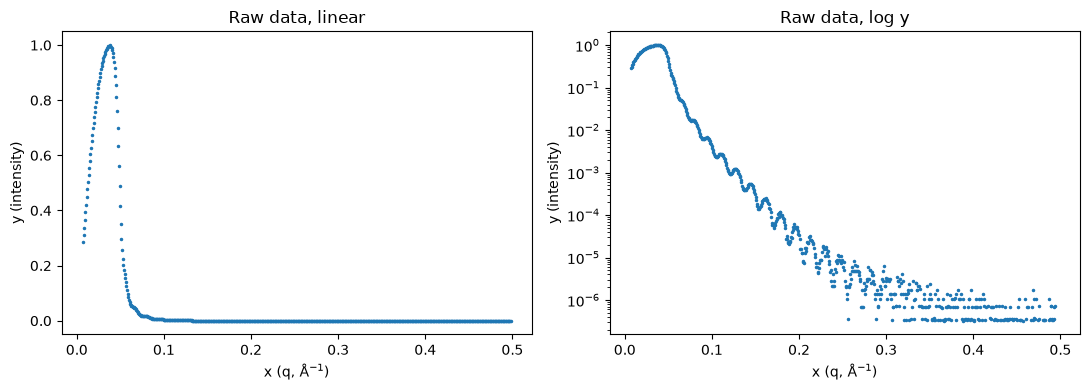

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(df['x'], df['y'], '.', ms=3)
ax1.set(xlabel='x (q, Å$^{-1}$)', ylabel='y (intensity)', title='Raw data, linear')

ax2.semilogy(df['x'], df['y'], '.', ms=3)
ax2.set(xlabel='x (q, Å$^{-1}$)', ylabel='y (intensity)', title='Raw data, log y')

plt.tight_layout()
plt.show()

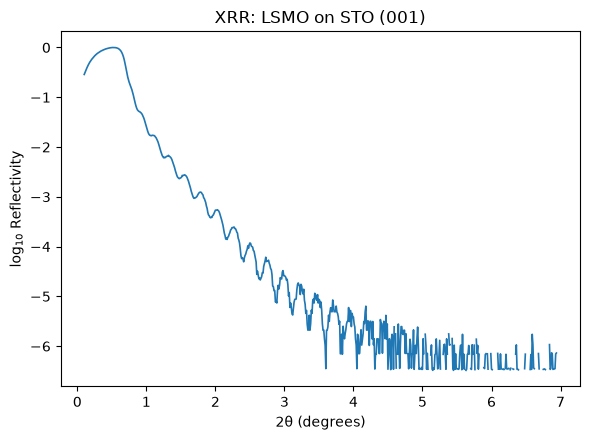

,x,two_theta,y,log_R
0,0.007118,0.10,0.286858,-0.542333
1,0.007830,0.11,0.310947,-0.507314
2,0.008542,0.12,0.337276,-0.472015
3,0.009254,0.13,0.365308,-0.437341
4,0.009965,0.14,0.392829,-0.405797


In [9]:
df['log_R'] = np.log10(df['y'].where(df['y'] > 0))    # zero-count points become NaN

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(df['two_theta'], df['log_R'], '-', lw=1.2)
ax.set(xlabel='2θ (degrees)', ylabel='log$_{10}$ Reflectivity',
       title='XRR: LSMO on STO (001)')
plt.tight_layout()
plt.show()

df[['x', 'two_theta', 'y', 'log_R']].head()

**Step 3: Define the sample. Edit this cell.**

- `wavelength`: X-ray wavelength in Å (Cu Kα = 1.5406), set in Step 1.
- `materials`: optical constants `(delta, beta)` at that wavelength. **To add a material, add a line.** Values are approximate (Cu Kα): please check them for your material, e.g. on the CXRO site (henke.lbl.gov).
- `stack`: layers from the **top** (air side) down to the substrate. **To add a layer, add a line.** Each number is `[start, min, max, vary]`; use `vary=False` to hold it fixed.
  - `t`: thickness (Å), `sigma`: roughness of the layer's top interface (Å), `dens`: density relative to bulk.
- `substrate`: material and roughness of the LSMO/STO interface (the interface above the substrate).
- `q_min`: kept above the footprint region (2θ below about 0.45°), where the beam overfills the sample and the intensity is not a true reflectivity.

In [10]:
# material: (delta, beta) at Cu K-alpha (approximate; verify for your material)
materials = {
    'LSMO': (1.82e-5, 1.5e-6),
    'STO':  (1.50e-5, 7.3e-7),
}

# top -> bottom.  [start, min, max, vary]
stack = [
    {'material': 'LSMO', 't': [350.0, 200.0, 500.0, True], 'sigma': [8.0, 0.0, 40.0, True], 'dens': [1.0, 0.7, 1.1, True]},  # LSMO film
]
substrate = {'material': 'STO', 'sigma': [5.0, 0.0, 30.0, True]}

scale = [1.0, 0.3, 5.0, True]       # overall intensity scale
bg    = [0.0, 0.0, 1e-6, False]     # constant background

q_min, q_max = 0.036, 0.235         # q-range used in the fit (Å^-1), about 2θ = 0.5° to 3.3°
global_search = True                # True = global search first (robust, slower), then local refinement

**Step 4:** The model (Parratt recursion with Névot–Croce roughness). Nothing to edit here.

In [11]:
k0 = 2 * np.pi / wavelength

def parratt(q, media, thickness, sigma):
    '''media: [(delta, beta)] vacuum..substrate; thickness: finite layers; sigma: roughness of each interface.'''
    kz = q / 2
    kzs = [np.sqrt(kz**2 - 2 * k0**2 * (d - 1j * b) + 0j) for d, b in media]
    r_tot = None
    for j in range(len(media) - 2, -1, -1):
        r = (kzs[j] - kzs[j+1]) / (kzs[j] + kzs[j+1]) * np.exp(-2 * kzs[j] * kzs[j+1] * sigma[j]**2)
        if r_tot is None:
            r_tot = r
        else:
            ph = np.exp(2j * kzs[j+1] * thickness[j])
            r_tot = (r + r_tot * ph) / (1 + r * r_tot * ph)
    return np.abs(r_tot)**2

# Build the flat list of fit parameters from the stack above
specs = {}                                  # name -> [start, min, max, vary]
for i, L in enumerate(stack):
    for key in ('t', 'sigma', 'dens'):
        specs['{}{}_{}'.format(L['material'], i + 1, key)] = L[key]
specs['substrate_sigma'] = substrate['sigma']
specs['scale'], specs['bg'] = scale, bg

names = list(specs)
free = [n for n in names if specs[n][3]]

def pack(vec):
    p = {n: specs[n][0] for n in names}
    p.update(dict(zip(free, vec)))
    return p

def model(p, q):
    media, thick, sig = [(0.0, 0.0)], [], []
    for i, L in enumerate(stack):
        m = L['material']
        d, b = materials[m]
        f = p['{}{}_dens'.format(m, i + 1)]
        media.append((d * f, b * f))
        thick.append(p['{}{}_t'.format(m, i + 1)])
        sig.append(p['{}{}_sigma'.format(m, i + 1)])
    media.append(materials[substrate['material']])
    sig.append(p['substrate_sigma'])
    return p['scale'] * parratt(q, media, thick, sig) + p['bg']

**Step 5:** Run the fit and print the thickness of each layer.

**Step 5:** Run the fit and print the thickness of each layer and final plot

rms of log10(R) residuals: 0.064

parameter              value   1-sigma
LSMO1_t                348.7   ± 0.162
LSMO1_sigma            7.898   ± 0.0365
LSMO1_dens            0.9957   ± 0.00776
substrate_sigma        5.035   ± 0.222
scale                  1.315   ± 0.0333
bg                         0   (fixed)

Thickness results
  LSMO     34.87 nm  (± 0.02)
  total    34.87 nm


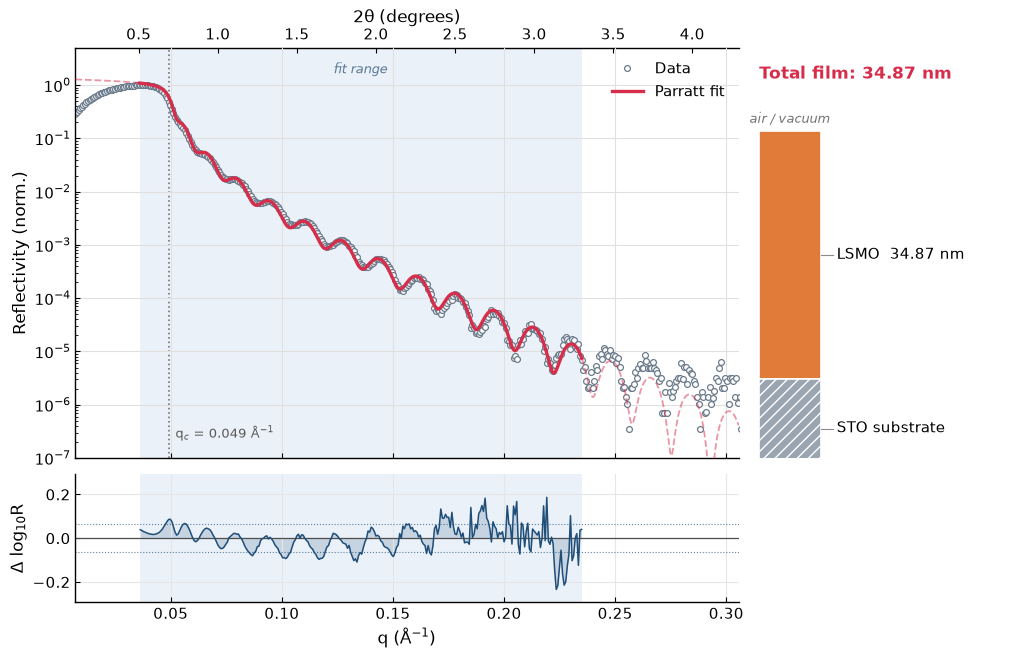

In [13]:
import re
from matplotlib.patches import Rectangle
from matplotlib.ticker import LogLocator, NullFormatter

mask = (q_all >= q_min) & (q_all <= q_max)
q_fit, R_fit = q_all[mask], R_all[mask]

def residuals(vec):
    return np.log10(np.maximum(model(pack(vec), q_fit), 1e-12)) - np.log10(R_fit)

x0 = [specs[n][0] for n in free]
lo = [specs[n][1] for n in free]
hi = [specs[n][2] for n in free]

if global_search:
    de = differential_evolution(lambda v: np.sum(residuals(v)**2), list(zip(lo, hi)),
                                seed=0, maxiter=300, popsize=20, polish=False)
    x0 = de.x
res = least_squares(residuals, x0, bounds=(lo, hi))
best = pack(res.x)

dof = max(len(q_fit) - len(free), 1)
cov = np.linalg.pinv(res.jac.T @ res.jac) * np.sum(res.fun**2) / dof
err = dict(zip(free, np.sqrt(np.diag(cov))))

print('rms of log10(R) residuals: {:.3f}\n'.format(np.sqrt(np.mean(res.fun**2))))
print('{:18s}{:>10s}   1-sigma'.format('parameter', 'value'))
for n in names:
    e = '± {:.3g}'.format(err[n]) if n in err else '(fixed)'
    at_bound = n in free and (np.isclose(best[n], specs[n][1]) or np.isclose(best[n], specs[n][2]))
    print('{:18s}{:10.4g}   {}{}'.format(n, best[n], e, '   <-- at a bound' if at_bound else ''))

print('\nThickness results')
total = 0.0
for i, L in enumerate(stack):
    key = '{}{}_t'.format(L['material'], i + 1)
    t = best[key]
    total += t
    e = err.get(key)
    print('  {:6s} {:7.2f} nm'.format(L['material'], t / 10) + ('  (± {:.2f})'.format(e / 10) if e else ''))
print('  total  {:7.2f} nm'.format(total / 10))

plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.linewidth': 1.0, 'xtick.direction': 'in', 'ytick.direction': 'in'})
c_data, c_fit, c_res, c_band = '#6b7b8c', '#d62d4b', '#1f4e79', '#e6eef7'
layer_colors = ['#e07b39', '#f2b134', '#4c78a8', '#2f9e8f', '#8e6bbf']   # one colour per layer (top to bottom)
c_sub = '#9aa5b1'
pretty = lambda m: re.sub(r'(\d+)', r'$_{\1}$', m)                       # Ta2O5 -> Ta$_2$O$_5$

x_hi = min(q_all.max(), 1.3 * q_max)                                     # show the fit range plus a little noise floor
q_plot = np.linspace(q_all.min(), x_hi, 3000)
R_plot = model(best, q_plot)

fig = plt.figure(figsize=(12, 7.2))
gs = fig.add_gridspec(2, 2, width_ratios=[4, 1.5], height_ratios=[3.2, 1], hspace=0.06, wspace=0.04)
ax  = fig.add_subplot(gs[0, 0])
axr = fig.add_subplot(gs[1, 0], sharex=ax)
axs = fig.add_subplot(gs[0, 1])

# shaded fit range on both panels
for a in (ax, axr):
    a.axvspan(q_min, q_max, color=c_band, alpha=0.8, lw=0, zorder=0)
ax.text((q_min + q_max) / 2, 0.965, 'fit range', transform=ax.get_xaxis_transform(),
        ha='center', va='top', fontsize=9.5, color='#5b7a99', style='italic')

# main panel: data, fit (solid inside the fit range, faint dashed outside)
ax.semilogy(q_all, R_all, 'o', ms=4.2, mfc='white', mec=c_data, mew=0.9, label='Data', zorder=2)
inside = (q_plot >= q_min) & (q_plot <= q_max)
ax.semilogy(q_plot[inside], R_plot[inside], '-', color=c_fit, lw=2.4, label='Parratt fit', zorder=4)
ax.semilogy(q_plot[q_plot < q_min], R_plot[q_plot < q_min], '--', color=c_fit, lw=1.3, alpha=0.5, zorder=3)
ax.semilogy(q_plot[q_plot > q_max], R_plot[q_plot > q_max], '--', color=c_fit, lw=1.3, alpha=0.5, zorder=3)
ax.set_xlim(q_all.min(), x_hi)
ax.set_ylim(1e-7, 5)
ax.set_ylabel('Reflectivity (norm.)', fontsize=12)
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=12))
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1, numticks=12))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.grid(True, which='major', color='0.88', lw=0.8)
ax.legend(frameon=False, loc='upper right', fontsize=11)
ax.tick_params(labelbottom=False)

# critical edge of the top layer, from the fitted density
top = stack[0]
d_top = materials[top['material']][0] * best['{}1_dens'.format(top['material'])]
q_c = 4 * np.pi * np.sqrt(2 * d_top) / wavelength
ax.axvline(q_c, color='0.45', ls=':', lw=1.2, zorder=1)
ax.text(q_c + 0.003, 0.04, 'q$_c$ = {:.3f} Å$^{{-1}}$'.format(q_c), transform=ax.get_xaxis_transform(),
        fontsize=9.5, color='0.35', ha='left', va='bottom')

# # summary box
# lines = []
# for i, L in enumerate(stack):
#     m = L['material']
#     lines.append('{}:  t = {:.2f} nm,  σ = {:.2f} nm,  density = {:.2f} × bulk'.format(
#         pretty(m), best['{}{}_t'.format(m, i + 1)] / 10, best['{}{}_sigma'.format(m, i + 1)] / 10,
#         best['{}{}_dens'.format(m, i + 1)]))
# lines.append('{}/{} interface:  σ = {:.2f} nm'.format(pretty(stack[-1]['material']), pretty(substrate['material']),
#                                                     best['substrate_sigma'] / 10))
# lines.append('rms (log$_{{10}}$R) = {:.2f}'.format(np.sqrt(np.mean(res.fun**2))))
# ax.text(0.97, 0.84, '\n'.join(lines), transform=ax.transAxes, ha='right', va='top', fontsize=10, color='0.2',
#         linespacing=1.5, bbox=dict(boxstyle='round,pad=0.55', fc='white', ec='0.8', lw=0.8))

# secondary x axis: 2theta (degrees)
sec = ax.secondary_xaxis('top',
        functions=(lambda x: np.degrees(2 * np.arcsin(np.clip(x * wavelength / (4 * np.pi), -1, 1))),
                   lambda t: 4 * np.pi * np.sin(np.radians(t) / 2) / wavelength))
sec.set_xlabel('2θ (degrees)', fontsize=12)
sec.spines['top'].set_visible(True)

# residual panel
rms = np.sqrt(np.mean(res.fun**2))
axr.axhline(0, color='0.3', lw=0.9)
axr.axhline(rms, color=c_res, lw=0.8, ls=':', alpha=0.7)
axr.axhline(-rms, color=c_res, lw=0.8, ls=':', alpha=0.7)
axr.fill_between(q_fit, res.fun, 0, color=c_res, alpha=0.18, lw=0)
axr.plot(q_fit, res.fun, '-', color=c_res, lw=1.1)
lim = 1.25 * max(np.abs(res.fun).max(), rms)
axr.set_ylim(-lim, lim)
axr.set_xlabel('q (Å$^{-1}$)', fontsize=12)
axr.set_ylabel('Δ log$_{10}$R', fontsize=12)
axr.grid(True, color='0.9', lw=0.8)
axr.set_xlim(q_all.min(), x_hi)

# side panel: sample sketch with thicknesses (top layer at the top)
sub_h, bar_w = 14.0, 0.5
t_nm = [best['{}{}_t'.format(L['material'], i + 1)] / 10 for i, L in enumerate(stack)]
H = sub_h + sum(t_nm)
y = H
bars = []                                                    # (label, colour, y_bottom, height)
for i, L in enumerate(stack):
    m = L['material']
    y -= t_nm[i]
    bars.append(('{}  {:.2f} nm'.format(pretty(m), t_nm[i]), layer_colors[i % len(layer_colors)], y, t_nm[i]))
bars.append(('{} substrate'.format(pretty(substrate['material'])), c_sub, 0.0, sub_h))
for lab, col, yb, h in bars:
    axs.add_patch(Rectangle((0, yb), bar_w, h, fc=col, ec='white', lw=1.2))
axs.add_patch(Rectangle((0, 0), bar_w, sub_h, fc='none', ec='white', hatch='///', lw=0))   # hatch the substrate
axs.text(bar_w / 2, H + H * 0.015, 'air / vacuum', ha='center', va='bottom', fontsize=9.5, color='0.45', style='italic')
# labels to the right, spread out so thin layers do not overlap
gap = H * 0.085
centers = [yb + h / 2 for _, _, yb, h in bars]
ly = []
for k, c in enumerate(centers):
    ly.append(c if k == 0 else min(c, ly[-1] - gap))
for (lab, col, yb, h), c, l in zip(bars, centers, ly):
    axs.plot([bar_w, bar_w + 0.1], [c, l], color='0.55', lw=0.8)
    axs.text(bar_w + 0.13, l, lab, va='center', ha='left', fontsize=10.5)
axs.text(0, H + H * 0.14, 'Total film: {:.2f} nm'.format(sum(t_nm)), fontsize=12, fontweight='bold', va='bottom',
         color=c_fit)
axs.set_xlim(-0.02, 2.0); axs.set_ylim(min(ly) - gap, H + H * 0.24); axs.axis('off')
plt.savefig('XRR_LSMO_fit.png', dpi=300, bbox_inches='tight')
plt.show()